# Wine Quality — проект по задачам регрессии

In [149]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.kernel_approximation import Nystroem

from catboost import CatBoostRegressor

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor

from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42

## Data load

In [ ]:
# red = pd.read_csv("/Users/nasy/Documents/ml_lr/ml_labs_mai/lr_1/data/winequality-red.csv", sep=";")
# white = pd.read_csv("/Users/nasy/Documents/ml_lr/ml_labs_mai/lr_1/data/winequality-white.csv", sep=";")

# print(red.shape)
# print(white.shape)

# red["wine_type"] = 'red'
# white["wine_type"] = 'white'
# df = pd.concat([red, white], ignore_index=True)

# df.to_csv("/Users/nasy/Documents/ml_lr/ml_labs_mai/Regression/data/winequality_full.csv", index=False)

df = pd.read_csv("/Users/nasy/Documents/ml_lr/ml_labs_mai/Regression/data/winequality_full.csv")

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [151]:
df.shape

(6497, 13)

## EDA

In [152]:
print(df.isna().sum())
print(f'\nПолных дубликатов: {df.duplicated().sum()}')

fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Полных дубликатов: 1177


In [153]:
df = df.drop_duplicates(keep='first')
df.shape

(5320, 13)

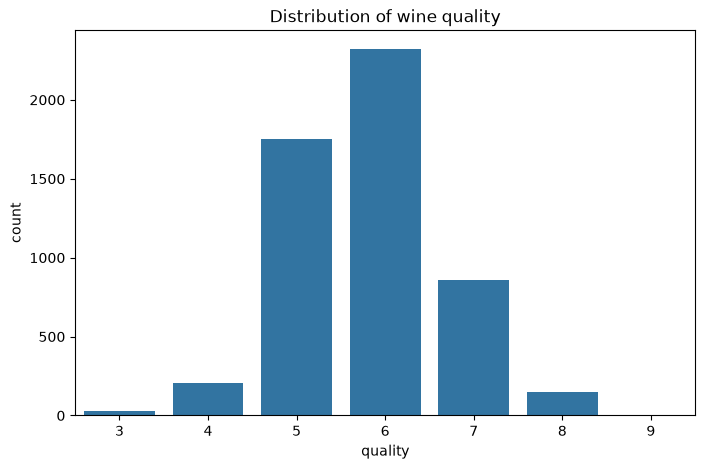

In [154]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of wine quality")
plt.show()

In [155]:
df.groupby("wine_type")["quality"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
wine_type,,,,,,
red,1359,5.623252,6.0,0.823578,3,8
white,3961,5.854835,6.0,0.890683,3,9


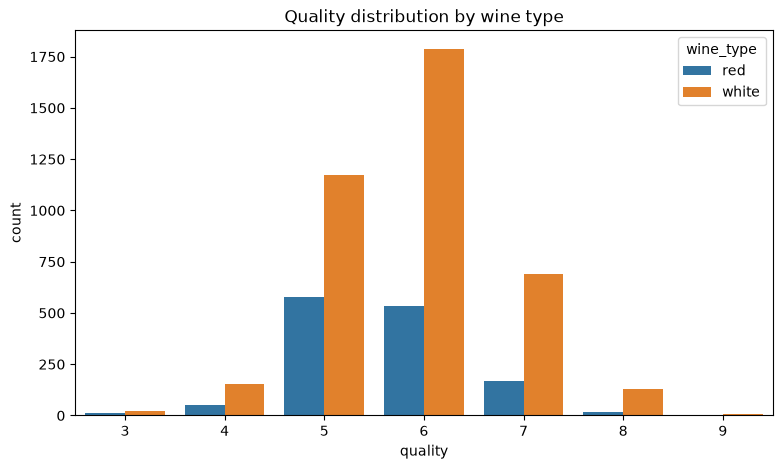

In [156]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="quality", hue="wine_type")
plt.title("Quality distribution by wine type")
plt.show()

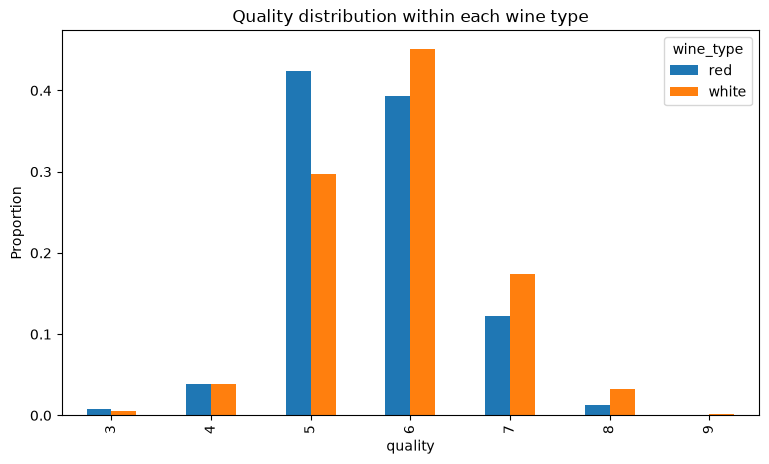

In [157]:
quality_by_type = pd.crosstab(
    df["quality"],
    df["wine_type"],
    normalize="columns"
)

quality_by_type.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Proportion")
plt.title("Quality distribution within each wine type")
plt.show()

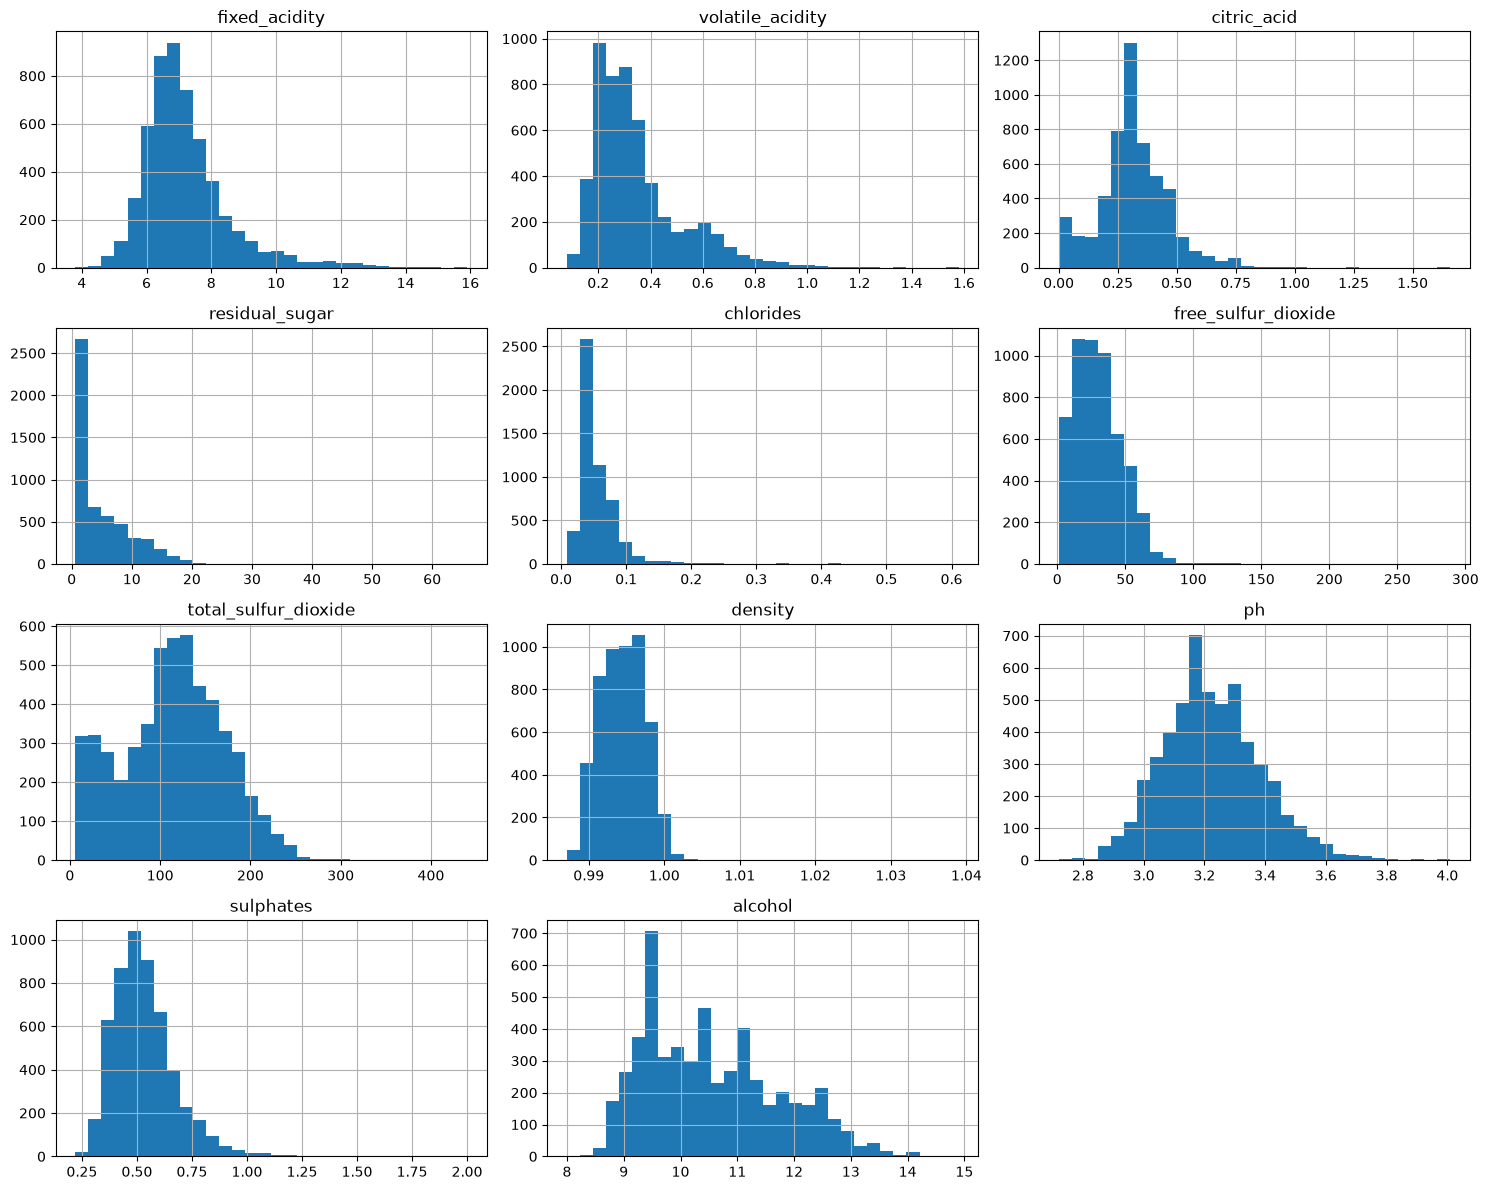

In [158]:
numeric_features = [
    col for col in df.columns
    if col not in ["quality", "wine_type"]
]

df[numeric_features].hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

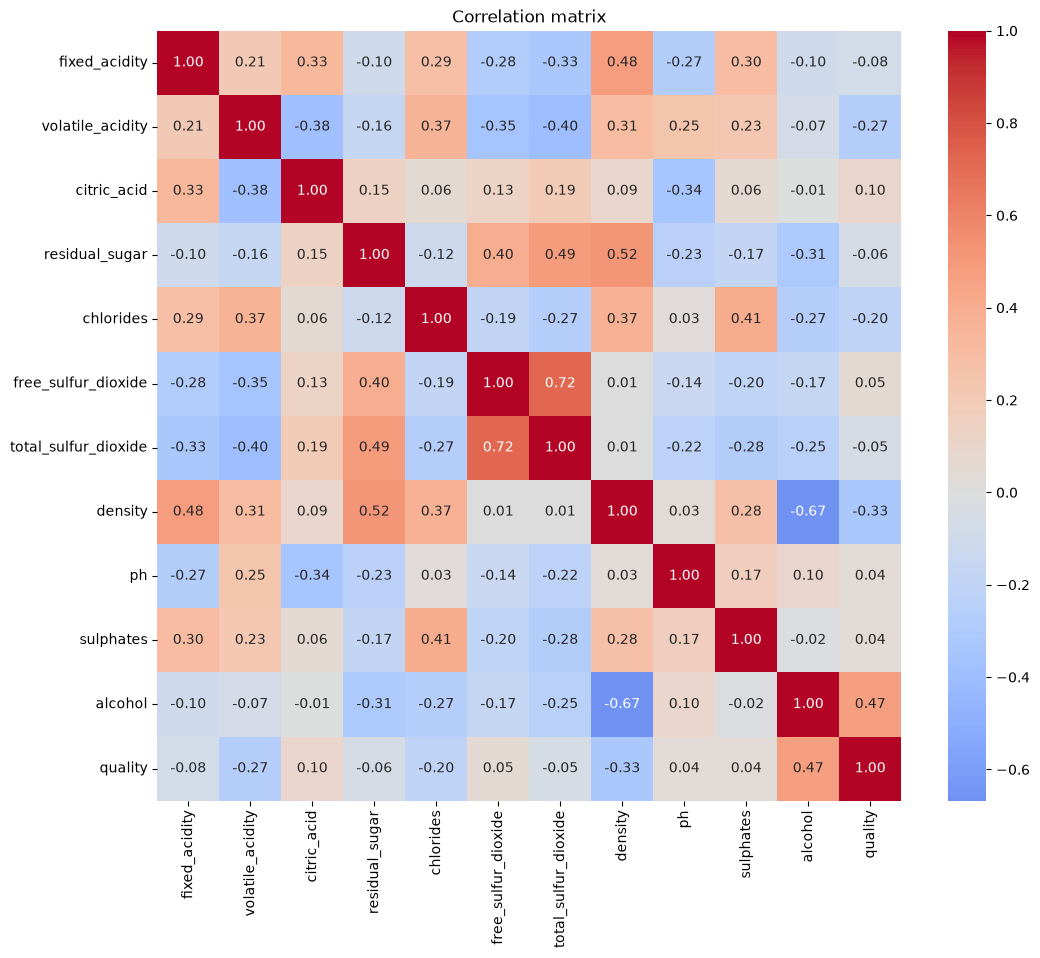

In [159]:
corr = df.drop(columns="wine_type").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()


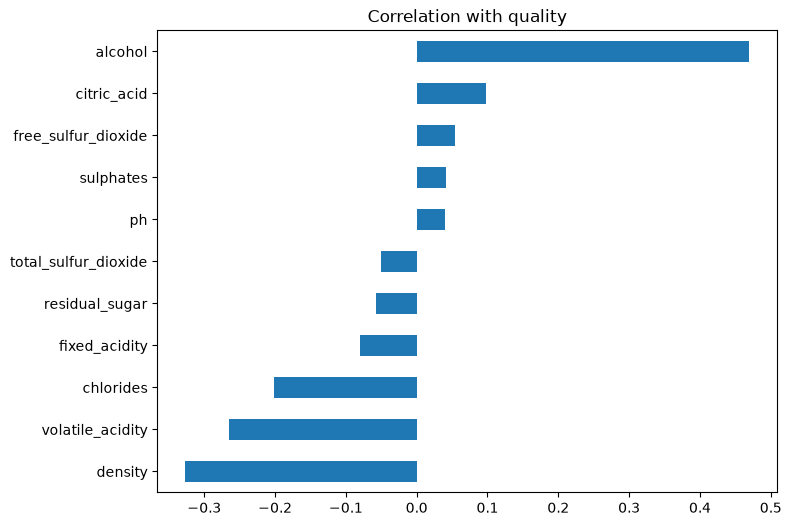

In [160]:
quality_corr = (
    corr["quality"]
    .drop("quality")
    .sort_values()
)

quality_corr.plot(kind="barh", figsize=(8, 6))
plt.title("Correlation with quality")
plt.show()

In [161]:
df["wine_type_binary"] = df["wine_type"].map({
    "red": 0,
    "white": 1
})

- критично скореллированных признаков нет
- таргет распределен неравномерно
- количество записей для красного и белого вина разное
- много дубликатов (примерно 1/6 от всех записей) - удалены

## X, y, train/test split

In [162]:
X = df.drop(columns=["quality", "wine_type"]).copy()
y = df["quality"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(4256, 12) (1064, 12)
(4256,) (1064,)


In [163]:
results = pd.DataFrame(
    columns=[
        "Model",
        "RMSE",
        "MAE"
    ]
)

## Baseline

In [164]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_rmse = root_mean_squared_error(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("RMSE:", baseline_rmse)
print("MAE:", baseline_mae)

RMSE: 0.8801023384558065
MAE: 0.694789576149019


In [165]:
results.loc[len(results)] = ["Baseline", baseline_rmse, baseline_mae]

## Linear Regression

In [166]:
rbf_scaler = StandardScaler()
X_train_rbf_scaled = rbf_scaler.fit_transform(X_train)
X_test_rbf_scaled = rbf_scaler.transform(X_test)

rbf = Nystroem(
    kernel="rbf",
    gamma=0.03,
    n_components=1200,
    random_state=42,
    n_jobs=-1
)

X_train_rbf = rbf.fit_transform(X_train_rbf_scaled)
X_test_rbf = rbf.transform(X_test_rbf_scaled)

rbf_ridge = Ridge(alpha=0.1)
rbf_ridge.fit(X_train_rbf, y_train)
rbf_pred = rbf_ridge.predict(X_test_rbf)

rbf_rmse = root_mean_squared_error(y_test,rbf_pred)
rbf_mae = mean_absolute_error(y_test, rbf_pred)

print("RMSE:", rbf_rmse)
print("MAE:", rbf_mae)

RMSE: 0.697308875744542
MAE: 0.5422309586132954


In [167]:
rbf_importance = []

for feature in X_test.columns:
    importance_values = []

    for i in range(10):
        X_test_permuted = X_test.copy()
        X_test_permuted[feature] = np.random.RandomState(i).permutation(
            X_test_permuted[feature].values
        )

        X_scaled = rbf_scaler.transform(X_test_permuted)
        X_rbf = rbf.transform(X_scaled)
        pred = rbf_ridge.predict(X_rbf)
        rmse = root_mean_squared_error(y_test, pred)

        importance_values.append(rmse - rbf_rmse)

    rbf_importance.append([feature, np.mean(importance_values)])

In [168]:
rbf_importance = pd.DataFrame(
    rbf_importance,
    columns=[
        "Feature",
        "Importance"
    ]
)

rbf_importance = rbf_importance.sort_values(
    "Importance",
    ascending=False
)

rbf_importance

,Feature,Importance
7,density,0.184376
11,wine_type_binary,0.168270
3,residual_sugar,0.094835
1,volatile_acidity,0.071692
6,total_sulfur_dioxide,0.069114
10,alcohol,0.062780
9,sulphates,0.050618
5,free_sulfur_dioxide,0.046623
0,fixed_acidity,0.029466
8,ph,0.025617


In [169]:
results.loc[len(results)] = ["Linear Regression", rbf_rmse, rbf_mae]

## Random Forest

In [170]:
rf = RandomForestRegressor(
    n_estimators=800,
    max_depth=None,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

rf_rmse = root_mean_squared_error(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)

print("RMSE:", rf_rmse)
print("MAE:", rf_mae)

results.loc[len(results)] = ["Random Forest", rf_rmse, rf_mae]

RMSE: 0.6849668439868986
MAE: 0.5300458176691729


In [171]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

rf_importance

,Feature,Importance
10,alcohol,0.259706
1,volatile_acidity,0.114112
5,free_sulfur_dioxide,0.092535
9,sulphates,0.079130
6,total_sulfur_dioxide,0.076275
8,ph,0.072302
3,residual_sugar,0.066436
4,chlorides,0.065280
2,citric_acid,0.058818
0,fixed_acidity,0.058583


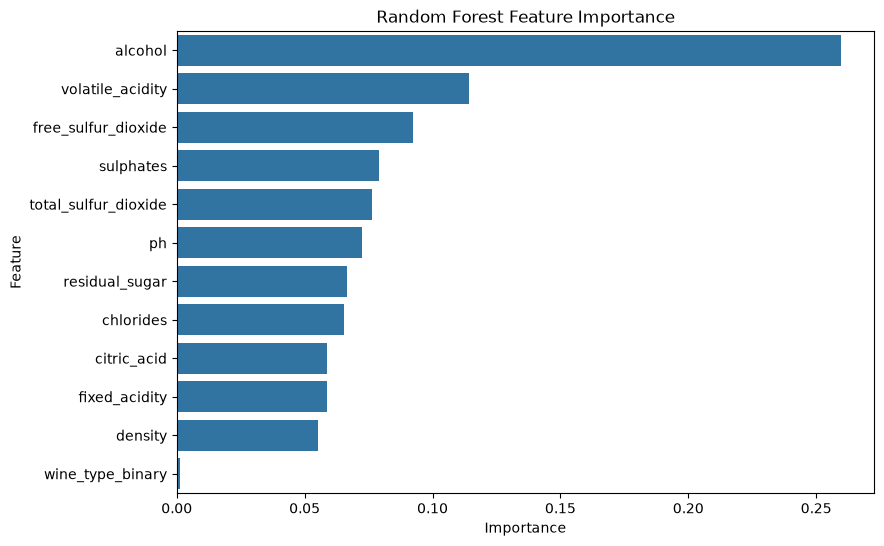

In [172]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

## Gradient Boosting

In [173]:
cat = CatBoostRegressor(
    depth=8,
    learning_rate=0.02,
    iterations=800,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cat.fit(X_train, y_train)
cat_pred = cat.predict(X_test)

cat_rmse = root_mean_squared_error(y_test, cat_pred)
cat_mae = mean_absolute_error(y_test, cat_pred)

print("RMSE:", cat_rmse)
print("MAE:", cat_mae)

results.loc[len(results)] = ["GradientBoosting", cat_rmse, cat_mae]


RMSE: 0.6834061177788844
MAE: 0.5283711801245797


In [174]:
cv_results_df = pd.DataFrame(results)

cv_results_df = (
    cv_results_df
    .sort_values("RMSE")
    .reset_index(drop=True)
)

cv_results_df


,Model,RMSE,MAE
0,GradientBoosting,0.683406,0.528371
1,Random Forest,0.684967,0.530046
2,Linear Regression,0.697309,0.542231
3,Baseline,0.880102,0.694790


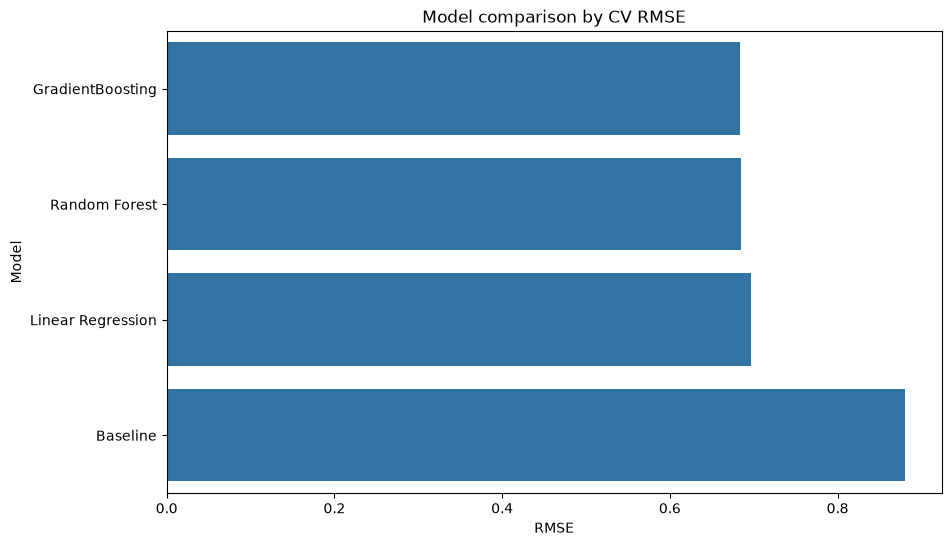

In [175]:
plt.figure(figsize=(10, 6))
sns.barplot(data=cv_results_df, x="RMSE", y="Model")
plt.title("Model comparison by CV RMSE")
plt.show()


In [176]:
best_name = 'GradientBoosting'

best_model = cat

best_model.fit(X_train, y_train)
best_pred = best_model.predict(X_test)

print("Best model:", best_name)


Best model: GradientBoosting


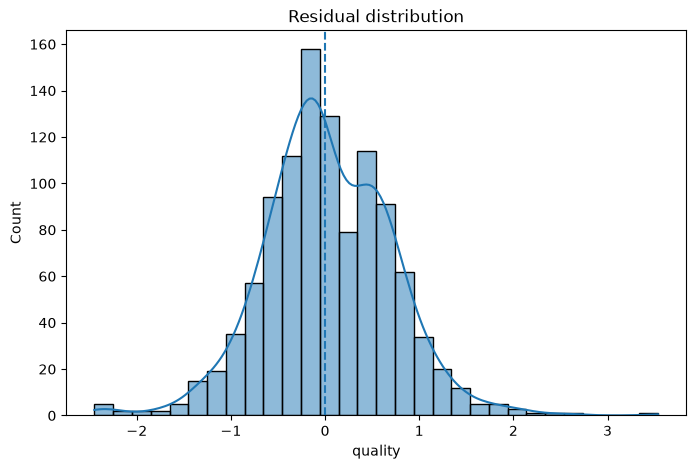

In [177]:
residuals = y_test - best_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.axvline(0, linestyle="--")
plt.title("Residual distribution")
plt.show()


In [178]:
cat.fit(X_train, y_train)

cat_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": cat.feature_importances_
})

cat_importance = cat_importance.sort_values(
    "importance",
    ascending=False
)

cat_importance


,feature,importance
10,alcohol,19.375202
1,volatile_acidity,12.482970
5,free_sulfur_dioxide,12.387722
9,sulphates,9.634436
8,ph,7.686739
6,total_sulfur_dioxide,6.843186
2,citric_acid,6.463469
3,residual_sugar,6.369818
4,chlorides,6.303114
0,fixed_acidity,5.339796


## ИТОГО
Выбранная модель - **Gradient Boosting**(CatBoost) с метрикой RMSE = 0.683406

Это ожидаемо, поскольку зависимость качества вина от физико-химических характеристик является нелинейной. Gradient Boosting  строятся последовательно: каждое новое дерево корректирует ошибки уже построенного ансамбля, что позволяет постепенно уменьшать как систематические ошибки модели, так и ошибку на более сложных наблюдениях. Небольшая глубина отдельных деревьев, малый learning rate помогают контролировать переобучение. Поэтому Gradient Boosting лучше описывает структуру данного датасета и показывает меньший RMSE.